# TP3 — Anexo: pipeline completo y tablas de detalle

> **Notebook auxiliar.** El notebook principal es `grupo_02_tp3.ipynb`. Este anexo corre el pipeline completo (~30 min con el dataset completo) y muestra todas las tablas de detalle.


**Grupo 2** · Jeremías Taran, Martín Gabriel Gómez, Jael Mataloni, Francisco Cisneros
**Diplomatura en Ciencia de Datos · Mentoría ID90Travel 2026**

## Pregunta

Dado un precio observado y la historia del mercado para su contexto, **¿es una oferta?** El TP3 diseña, valida y compara algoritmos que responden esa pregunta, y deja el elegido servido por una API.

## Qué resuelve este TP respecto de la devolución del TP2

| Observación del docente | Cómo se resolvió |
|---|---|
| Circularidad con `price_bucket` | `price_bucket` **no** entra al baseline ni al modelo. Se usa solo para diagnóstico de errores (sección 10), donde además se muestra empíricamente por qué sería leakage. |
| `is_deal` construida desde el precio | Los detectores ven solo la **historia 2024**; la etiqueta se calcula sobre el **mercado realizado 2025**. El ML no recibe mediana, z, percentiles ni bucket. |
| "30 de qué" | Regla única: **30 búsquedas independientes (`n_records`)** por celda. `demand_weight` queda como sensibilidad. |
| Fallback robusto | Cascada de 6 niveles + estado explícito `insufficient_data`; cada respuesta informa el nivel usado. |
| Outliers p99.9 sin cerrar | Corte calibrado solo en train + piso de 1 USD; sensibilidad p99 / p99.5 / p99.9 / sin corte (sección 11). |
| Consistencia texto vs números | Todo número sale de `outputs/<fuente>/`, generado por `src/hotel_deals/pipeline.py`. |

## Contenido

1. Ejecución del pipeline
2. Curación y política de outliers
3. Diseño experimental: split temporal y etiqueta de referencia
4. Baseline por contexto y cascada de fallback
5. Algoritmos comparados
6. Resultados sobre el test temporal (2025)
7. Control: split aleatorio vs temporal
8. Casos controlados (precios sintéticos)
9. Test set compartido evaluado de punta a punta con la API
10. Análisis de errores
11. Sensibilidad a la definición de mercado/contexto y a los umbrales
12. Decisión final
13. Limitaciones y próximos pasos

## 1. Ejecución del pipeline

El notebook no reimplementa nada: llama a `hotel_deals.pipeline.run`, que es el mismo código que corre `scripts/run_pipeline.py` y que alimenta la API. Fuente de datos:

- `SOURCE = "full"`: CSV históricos completos (2024 + 2025, ~5,1 M búsquedas). **Fuente oficial de los números del informe.** Requiere los CSV en `data/` o `HOTEL_DATA_DIR`.
- `SOURCE = "sample"`: muestra de 300.000 búsquedas (seed=42) incluida en el repo; corre en ~1,5 minutos.

In [1]:
import os
import sys
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from hotel_deals import config, pipeline  # noqa: E402

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

has_full = any(config.HISTORICALS_DIR.glob(config.HISTORICALS_PATTERN))
SOURCE = os.environ.get("TP3_SOURCE", "full" if has_full else "sample")
print(f"Fuente de datos: {SOURCE}")

R = pipeline.run(SOURCE)
S = R["summary"]

# Paleta: el algoritmo propuesto se destaca en azul; el resto en gris neutro.
BLUE, ORANGE, AQUA, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#ecebe7",
                     "axes.axisbelow": True, "font.size": 10, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})


def pct(x):
    return f"{100 * x:.1f}%"

Fuente de datos: full


2026-10-11 23:15:33,771 train=2512170 test=2633804


2026-10-11 23:23:43,692 F_ml_hist_gradient_boosting entrenado en 317s (umbral 0.41)


2026-10-11 23:27:37,297 G_ml_random_forest entrenado en 234s (umbral 0.35)


2026-10-11 23:42:22,578 Pipeline completo en 1817s


## 2. Curación y política de outliers

Se mantiene la curación del TP2 (precio estándar en USD por habitación-noche-persona) con dos cambios que cierran la observación sobre outliers:

1. **Piso inferior de 1 USD por habitación-noche-persona.** Valores menores son errores de carga (en la muestra eran ~0,2% de las filas) y, sin este piso, el detector los marcaría como "ofertas" espectaculares: el peor tipo de falso positivo para el negocio.
2. **Winsorización superior al p99.9 calculada solo con train (2024)** y aplicada igual a 2025 y a la API. En el TP2 el corte se calculaba sobre todo el dataset, lo que filtra información del test.

In [2]:
print(R["funnel"].assign(pct_retenido=lambda d: (100 * d["filas"] / d["filas"].iloc[0]).round(2)).to_string(index=False))
print(f"\nCorte de winsorización (p99.9 de train): {S['winsor_cap']:.0f} USD por habitación-noche-persona")
print(f"Train (check-in 2024): {S['n_train']:,} búsquedas | Test (check-in 2025): {S['n_test']:,} búsquedas")

                               etapa   filas  pct_retenido
                        Datos crudos 5158190        100.00
Denominadores válidos y noches <= 30 5158163        100.00
     Precio total en (0, 50.000] USD 5157438         99.99
  price_std >= 1 USD (piso de error) 5145974         99.76

Corte de winsorización (p99.9 de train): 1107 USD por habitación-noche-persona
Train (check-in 2024): 2,512,170 búsquedas | Test (check-in 2025): 2,633,804 búsquedas


## 3. Diseño experimental

### 3.1 Split temporal

- **Train = búsquedas con check-in en 2024.** Con esto se estiman los baselines, el corte de outliers, los encoders y los modelos de ML.
- **Test = búsquedas con check-in en 2025.** Ningún parámetro se ajusta con estos datos.

Es la situación real de producción: el sistema juzga precios nuevos con la historia disponible. Como control también se reporta un split aleatorio 80/20 dentro de 2024 (sección 7).

### 3.2 Etiqueta de referencia sin ground truth externo

No existe una etiqueta "esto fue una oferta". Se usa la regla adoptada en el TP2, pero aplicada sobre la **distribución realizada del mercado en el período evaluado**:

$$\text{is\_deal} = \left(z_{\log}^{(2025)} < -1\right) \land \left(1 - \frac{\text{price\_std}}{\text{mediana}^{(2025)}_{\text{contexto}}} \ge 0{,}20\right)$$

Lo que se evalúa entonces es: **¿la historia 2024 permite anticipar qué precios resultan oferta en el mercado 2025?** Los detectores nunca ven la mediana ni el desvío de 2025.

**Riesgo de circularidad que queda y cómo se controla.** Que la etiqueta use la misma familia de regla que el detector E le da una ventaja estructural. Por eso:
(a) el contraste de los detectores es temporal (2024 → 2025), no in-sample;
(b) se agrega un set de **precios sintéticos** donde la verdad se fija por construcción (sección 8);
(c) se compara contra modelos de ML que no conocen la regla.

### 3.3 Controles anti-leakage

| Elemento | Se ajusta con | Nunca usa |
|---|---|---|
| Corte de outliers | train | test |
| Baselines de la cascada | train | test |
| Encoders y umbral de probabilidad del ML | train (80% ajuste / 20% calibración) | test |
| `price_bucket` | train (solo para diagnóstico) | — no es feature ni dimensión |
| Etiqueta de test | mercado 2025 | — no la ve ningún detector |

In [3]:
print(f"Búsquedas de test con etiqueta definida: {S['n_test_evaluable']:,} ({pct(S['test_evaluable_pct'])})")
print(f"Prevalencia de ofertas — train: {pct(S['train_prevalence'])} | test: {pct(S['test_prevalence'])}")

Búsquedas de test con etiqueta definida: 2,609,281 (99.1%)
Prevalencia de ofertas — train: 15.1% | test: 15.0%


El resto de las búsquedas de 2025 no tiene soporte ni siquiera a nivel país dentro del propio 2025, así que no se les puede asignar etiqueta y quedan fuera de la evaluación de clasificación (sí cuentan en la cobertura operativa de la sección 4).

## 4. Baseline por contexto y cascada de fallback

El contexto del TP2 (`destino × mes × semana × estadía`) solo tiene 30 búsquedas independientes en una fracción chica de celdas. Para no quedarse sin respuesta se usa una cascada: cada búsqueda toma el **nivel más específico con `n_records ≥ 30`**.

| Nivel | Claves |
|---|---|
| L1 | destino × mes × semana × estadía |
| L2 | destino × mes × estadía |
| L3 | destino × mes |
| L4 | destino × estadía |
| L5 | destino |
| L6 | país × mes × estadía |
| L7 | sin soporte → `insufficient_data` (no decide) |

**Fallback geográfico.** Las ciudades que no matchean contra `destination_with_nearest.csv` se conservan como mercado propio (`city:<país>:<ciudad>`). En el TP2 se usaba el nombre crudo, que mezclaba ciudades homónimas de distintos países. Si esa ciudad tampoco tiene historia suficiente, sube a país (L6).

                            pct_busquedas_test  pct_busquedas_train_oraculo
nivel                                                                      
L1_dest_mes_semana_estadia               44.21                        49.01
L2_dest_mes_estadia                      23.15                        23.25
L3_dest_mes                              10.34                         9.66
L4_dest_estadia                          12.22                         9.41
L5_dest                                   3.48                         3.15
L6_pais_mes_estadia                       5.54                         5.02
L7_sin_soporte                            1.07                         0.50

Cobertura operativa sobre TODAS las búsquedas 2025: 98.9%


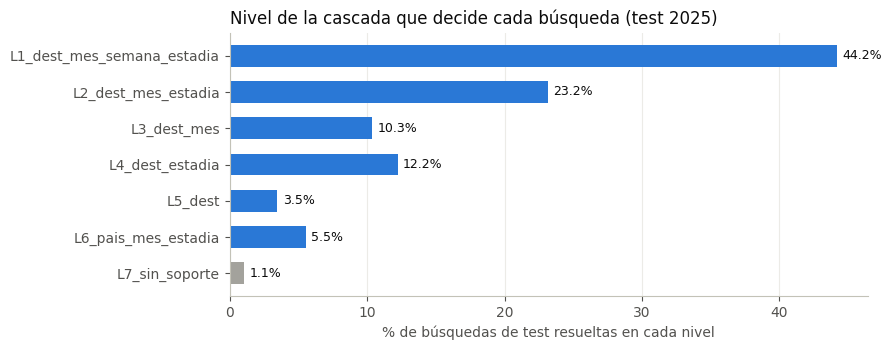

In [4]:
lc = R["level_coverage"]
print((100 * lc).round(2).to_string())
op_cov = 1 - lc.loc[config.NO_SUPPORT_LEVEL, "pct_busquedas_test"]
print(f"\nCobertura operativa sobre TODAS las búsquedas 2025: {pct(op_cov)}")

fig, ax = plt.subplots(figsize=(9, 3.6))
vals = 100 * lc["pct_busquedas_test"].iloc[::-1]
colors = [GRAY if i == config.NO_SUPPORT_LEVEL else BLUE for i in vals.index]
ax.barh(vals.index, vals.values, color=colors, height=0.6)
for y, v in enumerate(vals.values):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", color=INK, fontsize=9)
ax.set_xlabel("% de búsquedas de test resueltas en cada nivel")
ax.set_title("Nivel de la cascada que decide cada búsqueda (test 2025)", loc="left", color=INK)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 5. Algoritmos comparados

| # | Algoritmo | Regla | Usa la cascada |
|---|---|---|---|
| A | Naive aleatorio | marca al azar con probabilidad = prevalencia de train | no |
| B | Naive por mediana | precio ≤ 80% de la mediana histórica del contexto | sí |
| C | Z-score gaussiano (docente) | $z < -1$ | sí |
| D | Percentil 10 | precio < p10 histórico del contexto | sí |
| **E** | **Híbrido (propuesto)** | $z_{\log} < -1$ y descuento ≥ 20% | **sí** |
| E2 | Híbrido sin semana (*post-hoc*) | igual a E, con la cascada desde L2 | sí (L2..L6) |
| F | HistGradientBoosting | features exógenas* | no (decide siempre) |
| G | Random Forest | features exógenas* | no (decide siempre) |

\* destino (top 250 de train, resto "otro"), país, mes, semana, día de la semana, noches, adultos, niños, habitaciones, `avg_hotel_count` y log del precio. **Sin `price_bucket`, sin mediana, sin z, sin percentiles.** El modelo tiene que aprender por sí mismo qué precio es bajo en cada contexto. El umbral de probabilidad se calibra maximizando F1 en un 20% de train separado.

**E2 es post-hoc:** surgió del análisis de sensibilidad (sección 11) mirando el test 2025. Se reporta para transparencia, pero **no se usa para elegir el algoritmo final**: adoptarlo exigiría confirmarlo sobre datos nuevos (por ejemplo, 2026).

**Cambio respecto del plan del TP2:** se usan HistGradientBoosting y RandomForest de scikit-learn en lugar de LightGBM/XGBoost. HistGradientBoosting implementa el mismo algoritmo (boosting por histogramas con categorías nativas) y evita dependencias pesadas en la imagen Docker.

## 6. Resultados (2025)

**Métricas elegidas y por qué:**

- **Precision y tasa de falsos positivos (FPR)** son las prioritarias: recomendar como oferta algo que no lo es erosiona la confianza del usuario en el producto.
- **Recall** mide cuántas oportunidades reales se le muestran al usuario.
- **F1** resume el balance precision/recall y es el criterio principal de selección.
- **Cobertura** = % de búsquedas evaluables donde el sistema decide. Un detector con métricas perfectas sobre el 2% de los casos no sirve.
- **Accuracy** solo como referencia: con ~15% de prevalencia, marcar "no oferta" siempre ya da ~85%.

Las métricas de clasificación se calculan sobre los casos donde cada algoritmo decide.

,accuracy,precision,recall,f1,fpr,cobertura,tasa_marcados
algoritmo,,,,,,,
A_naive_aleatorio,0.744,0.151,0.151,0.151,0.150,1.000,0.151
B_naive_mediana_20,0.752,0.375,0.965,0.540,0.285,0.998,0.387
C_zscore_gaussiano,0.900,0.783,0.461,0.580,0.023,0.998,0.089
D_percentil_10,0.923,0.760,0.718,0.738,0.040,0.998,0.142
E_hibrido_cascada,0.925,0.725,0.806,0.764,0.054,0.998,0.167
E2_hibrido_sin_semana_posthoc,0.929,0.745,0.806,0.775,0.049,0.998,0.163
F_ml_hist_gradient_boosting,0.929,0.756,0.785,0.770,0.045,1.000,0.156
G_ml_random_forest,0.916,0.713,0.743,0.728,0.053,1.000,0.157


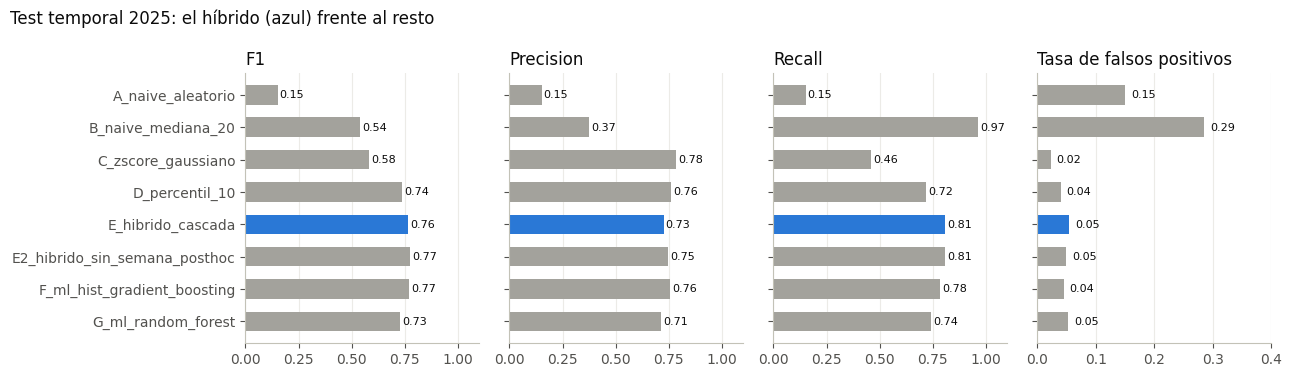

In [5]:
m = R["metrics"].set_index("algoritmo")
cols = ["accuracy", "precision", "recall", "f1", "fpr", "cobertura", "tasa_marcados"]
display(m[cols].round(3))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
order = m.index[::-1]
for ax, metric, title in zip(axes, ["f1", "precision", "recall", "fpr"],
                             ["F1", "Precision", "Recall", "Tasa de falsos positivos"]):
    v = m.loc[order, metric]
    ax.barh(order, v, color=[BLUE if a.startswith("E_") else GRAY for a in order], height=0.6)
    for y, x in enumerate(v):
        ax.text(x + 0.01, y, f"{x:.2f}", va="center", fontsize=8, color=INK)
    ax.set_title(title, loc="left", color=INK)
    ax.set_xlim(0, 1.1 if metric != "fpr" else max(0.4, v.max() * 1.25))
    ax.grid(axis="y", visible=False)
fig.suptitle("Test temporal 2025: el híbrido (azul) frente al resto", x=0.01, ha="left", color=INK)
plt.tight_layout()
plt.show()

**Ponderando por demanda (`count_repeated`).** Mismas métricas, pero cada búsqueda pesa según cuántas veces se repitió: es la vista "por usuario expuesto".

In [6]:
display(R["metrics_weighted"].set_index("algoritmo")[cols].round(3))

,accuracy,precision,recall,f1,fpr,cobertura,tasa_marcados
algoritmo,,,,,,,
A_naive_aleatorio,0.805,0.063,0.147,0.088,0.150,1.000,0.150
B_naive_mediana_20,0.745,0.196,0.966,0.325,0.270,0.999,0.315
C_zscore_gaussiano,0.953,0.722,0.431,0.540,0.011,0.999,0.038
D_percentil_10,0.958,0.661,0.686,0.673,0.024,0.999,0.066
E_hibrido_cascada,0.957,0.631,0.778,0.697,0.031,0.999,0.078
E2_hibrido_sin_semana_posthoc,0.963,0.689,0.773,0.729,0.024,0.999,0.071
F_ml_hist_gradient_boosting,0.965,0.712,0.761,0.736,0.021,1.000,0.068
G_ml_random_forest,0.960,0.673,0.712,0.692,0.024,1.000,0.067


## 7. Control: split aleatorio vs temporal

Mismo procedimiento, pero con un 80/20 aleatorio dentro de 2024 (baselines con el 80%; etiqueta sobre el mercado 2024 completo).

In [7]:
cmp = pd.DataFrame({
    "F1 aleatorio 2024": R["metrics_random"].set_index("algoritmo")["f1"],
    "F1 temporal 2025": m["f1"],
})
cmp["caída"] = cmp["F1 temporal 2025"] - cmp["F1 aleatorio 2024"]
display(cmp.round(3))

,F1 aleatorio 2024,F1 temporal 2025,caída
algoritmo,,,
A_naive_aleatorio,0.150,0.151,0.001
B_naive_mediana_20,0.567,0.540,-0.027
C_zscore_gaussiano,0.636,0.580,-0.057
D_percentil_10,0.832,0.738,-0.094
E2_hibrido_sin_semana_posthoc,NaN,0.775,NaN
E_hibrido_cascada,0.919,0.764,-0.155
F_ml_hist_gradient_boosting,0.808,0.770,-0.038
G_ml_random_forest,NaN,0.728,NaN


El split aleatorio es optimista: train y test comparten el mismo mercado, y en el caso de E la etiqueta y el detector se calculan casi sobre los mismos datos. La caída al pasar a 2025 mide el efecto de que **el mercado cambia de un año a otro** (deriva de precios). Por eso las conclusiones se toman del split temporal.

## 8. Casos controlados: precios sintéticos

Se toman búsquedas reales de 2025 (estratificadas por tipo de destino) y se reemplaza su precio por **factor × mediana del mercado realizado**: 0.3, 0.4, 0.5, 0.7, 0.85, 1.0, 1.3, 1.5. Así se ve cómo responde cada algoritmo a descuentos conocidos, incluido el **-30% (factor 0.7)** que sugirió el docente y los casos caros.

La fila **VERDAD** aplica la definición de oferta al precio sintético con los parámetros del mercado 2025.

factor_precio,0.30,0.40,0.50,0.70,0.85,1.00,1.30,1.50
algoritmo,,,,,,,,
B_naive_mediana_20,99.0,96.0,91.6,73.2,38.6,15.1,4.7,2.3
C_zscore_gaussiano,55.7,43.3,27.2,4.0,1.7,0.3,0.0,0.0
D_percentil_10,82.9,64.8,39.3,7.4,2.7,1.3,0.3,0.0
E_hibrido_cascada,89.3,75.8,48.7,8.7,3.0,2.0,0.3,0.0
F_ml_hist_gradient_boosting,90.3,70.7,40.3,9.7,4.3,1.7,0.7,0.3
G_ml_random_forest,66.3,46.7,30.3,11.0,6.3,4.7,2.3,2.0
VERDAD (regla sobre mercado 2025),98.0,84.0,43.7,2.7,0.0,0.0,0.0,0.0


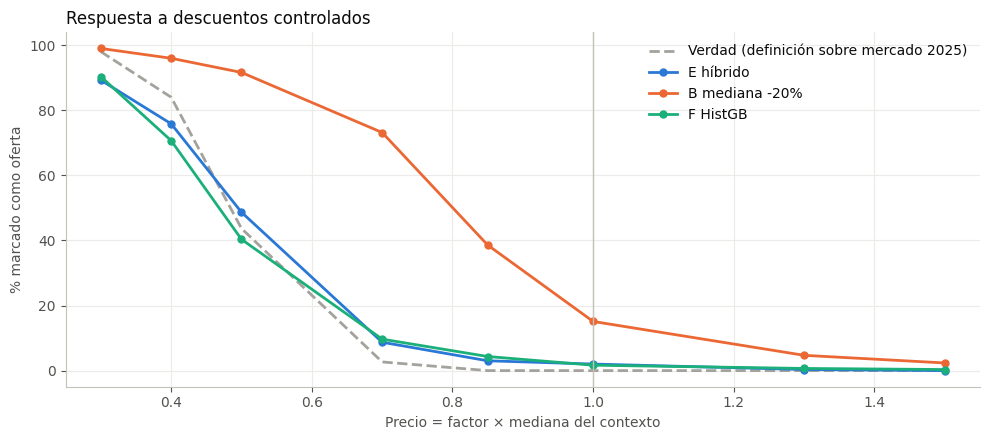

In [8]:
sf = R["synthetic_by_factor"]
display((100 * sf).round(1))

fig, ax = plt.subplots(figsize=(10, 4.5))
show = [("E_hibrido_cascada", BLUE, "E híbrido"), ("B_naive_mediana_20", ORANGE, "B mediana -20%"),
        ("F_ml_hist_gradient_boosting", AQUA, "F HistGB")]
x = sf.columns.astype(float)
truth = sf.loc["VERDAD (regla sobre mercado 2025)"]
ax.plot(x, 100 * truth, color=GRAY, lw=2, ls="--", label="Verdad (definición sobre mercado 2025)")
for key, c, lab in show:
    if key in sf.index:
        ax.plot(x, 100 * sf.loc[key], color=c, lw=2, marker="o", ms=5, label=lab)
ax.axvline(1.0, color="#c3c2b7", lw=1)
ax.set_xlabel("Precio = factor × mediana del contexto")
ax.set_ylabel("% marcado como oferta")
ax.set_title("Respuesta a descuentos controlados", loc="left", color=INK)
ax.legend(frameon=False, loc="upper right")
ax.set_xlim(0.25, 1.55)
plt.tight_layout()
plt.show()

**Lectura.**

- Con la dispersión real de los mercados, un precio 30% por debajo de la mediana **no** es estadísticamente anómalo. Según la propia definición, solo una fracción mínima de esos casos es oferta. Los mercados mezclan categorías de hotel, y un -30% suele ser simplemente un hotel económico. La definición recién marca oferta de forma consistente con descuentos de **60% o más** (factor ≤ 0.4).
- E y F siguen bien esa curva: marcan casi todo en 0.3, muy poco en 0.7 y prácticamente nada en precios iguales o mayores a la mediana. Random Forest responde peor al precio.
- La regla naive por mediana marca el -30%, pero también marca como oferta una parte de los precios **iguales** a la mediana 2025: el mercado se movió respecto de 2024 (ver sección 10).

## 9. Test set 

Archivo: `data/test_set/test_set_<fuente>.csv`. Está en el **formato de query de la API**, así que cualquiera puede reevaluarlo enviándolo a `/evaluate/batch`.

| Bloque | Cómo se construyó | Para qué |
|---|---|---|
| `real` | Búsquedas 2025 deduplicadas, estratificadas por tipo de destino (top50 / medio / cola / sin mapeo) × estadía × etiqueta (hasta 150 por estrato) | Cubrir todo el espectro de destinos y contextos, con clases balanceadas |
| `sintetico` | Sección 8 (8 factores de precio) | Fortalezas y debilidades frente a descuentos conocidos |
| `borde` | 11 casos armados a mano | Fallback y validaciones: ciudad inexistente, país inexistente, ciudad nula, precio absurdo, noches fuera de rango, grupo grande, nombre sin acentos |

Como el bloque real está balanceado por diseño (50% ofertas), su precision no es comparable con la del test poblacional de la sección 6.

In [9]:
print(pd.Series(S["test_set_rows"]).rename("filas").to_string())
display(R["test_set_metrics"].set_index("bloque")[["n_evaluables", "cobertura", "precision", "recall", "f1", "fpr", "prevalencia"]].round(3))
display(R["edge_eval"])

real         3600
sintetico    2400
borde          11


,n_evaluables,cobertura,precision,recall,f1,fpr,prevalencia
bloque,,,,,,,
real,3600,0.997,0.918,0.808,0.860,0.072,0.500
sintetico,2400,0.993,0.813,0.813,0.813,0.074,0.285


,query_id,descripcion,expected_decision,api_decision,api_baseline_level,ok
6000,q06000,"Destino top, precio 80% bajo la mediana",deal,deal,L1_dest_mes_semana_estadia,True
6001,q06001,"Destino top, precio 3x la mediana",no_deal,no_deal,L1_dest_mes_semana_estadia,True
6002,q06002,Ciudad inexistente en país conocido -> fallbac...,deal|no_deal,no_deal,L6_pais_mes_estadia,True
6003,q06003,Ciudad nula -> fallback país,deal|no_deal,no_deal,L6_pais_mes_estadia,True
6004,q06004,País inexistente -> sin soporte,insufficient_data,insufficient_data,L7_sin_soporte,True
6005,q06005,Ciudad sin mapeo con historia propia,deal|no_deal,no_deal,L1_dest_mes_semana_estadia,True
6006,q06006,Precio absurdo (< 1 USD por persona-noche),invalid_price,invalid_price,L1_dest_mes_semana_estadia,True
6007,q06007,Noches = 0,invalid_input,invalid_input,L1_dest_mes_semana_estadia,True
6008,q06008,Noches = 45 (fuera de rango),invalid_input,invalid_input,L1_dest_mes_semana_estadia,True
6009,q06009,"Grupo grande: 6 adultos, 2 niños, 3 hab, 7 noches",deal|no_deal,no_deal,L1_dest_mes_semana_estadia,True


## 10. Análisis de errores

### 10.1 ¿Dónde falla el híbrido?

In [10]:
err = R["errors"]
cols_e = ["n_evaluables", "precision", "recall", "f1", "fpr", "prevalencia"]
for g, title in [("base_level", "Nivel de la cascada"), ("tier", "Tipo de destino"), ("mapeo", "Mapeo geográfico"),
                 ("stay_duration", "Duración de estadía"), ("month", "Mes de check-in")]:
    print(f"\n— {title}")
    print(err[g].set_index(g)[cols_e].round(3).to_string())


— Nivel de la cascada
                            n_evaluables  precision  recall     f1    fpr  prevalencia
base_level                                                                            
L1_dest_mes_semana_estadia       1164398      0.764   0.866  0.812  0.040        0.130
L2_dest_mes_estadia               609855      0.690   0.757  0.722  0.050        0.129
L3_dest_mes                       272250      0.679   0.796  0.733  0.124        0.247
L4_dest_estadia                   321754      0.677   0.709  0.693  0.058        0.145
L5_dest                            91132      0.742   0.809  0.774  0.108        0.277
L6_pais_mes_estadia               145552      0.816   0.806  0.811  0.034        0.156
L7_sin_soporte                      4340        NaN     NaN  0.000    NaN          NaN

— Tipo de destino
           n_evaluables  precision  recall     f1    fpr  prevalencia
tier                                                                 
cola             181622      0.723 

### 10.2 ¿Por qué falla? Perfil de falsos positivos y falsos negativos

`cambio_mediana_mercado` = mediana 2025 / mediana 2024 del contexto − 1.

In [11]:
display(R["error_profile"].round(3))

,error_tipo,n,descuento_mediano,z_log_mediano,cambio_mediana_mercado,soporte_mediano
0,FN,75970,0.412,-0.733,0.251,61.0
1,FP,119546,0.542,-1.201,-0.204,69.0
2,ok,2409425,-0.008,0.063,-0.010,76.0


**Otros patrones:** el híbrido rinde mejor en los 50 destinos principales que en la cola y en las ciudades sin mapeo. Los niveles de fallback que mezclan estadías (L3 destino × mes, L5 destino) tienen el doble de FPR que el resto. Noviembre y diciembre pierden recall, lo que es consistente con que el último tramo de 2025 tenga menos historia comparable.

Los errores no vienen de precios ambiguos cerca del umbral, sino de **deriva del mercado entre años**:

- **Falsos positivos:** contextos donde el mercado 2025 se abarató respecto de 2024. Un precio que en la historia parecía muy bajo es normal en el mercado nuevo.
- **Falsos negativos:** contextos donde el mercado 2025 se encareció. Un precio que en 2025 es oferta no lo parece contra la historia.

Implicancia operativa: los baselines tienen que **refrescarse periódicamente** (ventana móvil) en lugar de calcularse una sola vez.

### 10.3 `price_bucket`: demostración empírica del leakage

Se calcula `price_bucket` con umbrales de train solo para diagnosticar. Resultado:

In [12]:
print(err["price_bucket"].set_index("price_bucket")[cols_e].round(3).to_string())

              n_evaluables  precision  recall     f1    fpr  prevalencia
price_bucket                                                            
high                657844      0.174   0.174  0.174  0.001        0.001
low                 678077      0.789   0.867  0.826  0.199        0.461
medium             1273360      0.493   0.572  0.529  0.039        0.062


La prevalencia de ofertas es prácticamente **0% en `high`** y altísima en `low`: el bucket es casi la etiqueta. Si se usara como feature, un modelo aprendería "low ⇒ oferta" y tendría métricas infladas sin detectar nada. Esto confirma la observación del docente y justifica haberlo dejado afuera del modelo y del baseline.

## 11. Sensibilidad

La etiqueta se mantiene fija (definición por defecto) y se varía **solo el detector**. En el bloque de winsorización cambia el dato, así que se recalculan baseline y etiqueta.

In [13]:
sens = R["sensitivity"]
for b, sub in sens.groupby("bloque", sort=False):
    print(f"\n— {b}")
    print(sub.drop(columns="bloque").set_index("variante").round(3).to_string())


— soporte_minimo (n_records)
          precision  recall     f1    fpr  cobertura  tasa_marcados  prevalencia
variante                                                                        
>= 10         0.683   0.774  0.726  0.064      1.000          0.170         0.15
>= 30         0.725   0.806  0.764  0.054      0.998          0.167         0.15
>= 50         0.720   0.798  0.757  0.055      0.996          0.167         0.15
>= 100        0.694   0.775  0.732  0.060      0.989          0.167         0.15

— unidad de soporte
                     precision  recall     f1    fpr  cobertura  tasa_marcados  prevalencia
variante                                                                                   
demand_weight >= 30      0.691   0.786  0.736  0.062        1.0          0.171         0.15

— definición de contexto
                                 precision  recall     f1    fpr  cobertura  tasa_marcados  prevalencia
variante                                                 

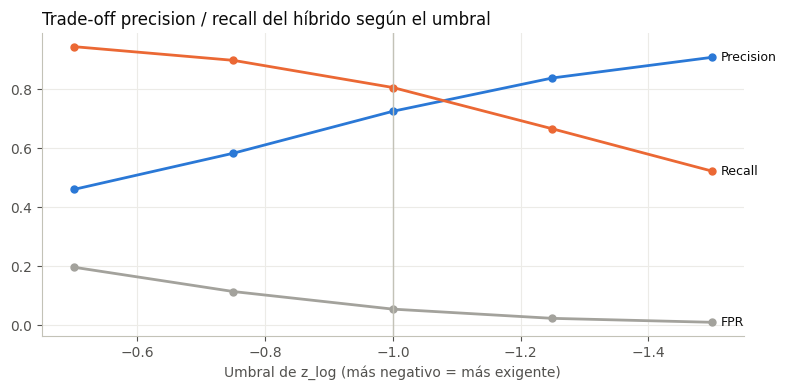

In [14]:
zt = sens[sens["bloque"].str.startswith("umbral z_log")].copy()
zt["z"] = zt["variante"].str.extract(r"(-?\d+\.?\d*)").astype(float)
fig, ax = plt.subplots(figsize=(8, 4))
for col, c, lab in [("precision", BLUE, "Precision"), ("recall", ORANGE, "Recall"), ("fpr", GRAY, "FPR")]:
    ax.plot(zt["z"], zt[col], color=c, lw=2, marker="o", ms=5)
    ax.annotate(lab, (zt["z"].iloc[-1], zt[col].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                color=INK, fontsize=9, va="center")
ax.axvline(-1.0, color="#c3c2b7", lw=1)
ax.set_xlabel("Umbral de z_log (más negativo = más exigente)")
ax.set_title("Trade-off precision / recall del híbrido según el umbral", loc="left", color=INK)
ax.invert_xaxis()
plt.tight_layout()
plt.show()

**Lecturas de la sensibilidad:**

1. **Soporte mínimo:** bajar a 10 búsquedas aumenta cobertura pero degrada precision (baselines ruidosos); subir a 100 pierde cobertura sin mejorar. 30 queda en el punto de equilibrio.
2. **`demand_weight` vs `n_records`:** contar demanda ponderada infla el soporte con búsquedas repetidas y empeora precision y FPR. Esto confirma la decisión de contar búsquedas independientes.
3. **Contexto:**
   - Sin fallback (solo L1) se gana precision, pero se decide sobre menos de la mitad de los casos.
   - **Sacar la semana del mes mejora el resultado** (más precision y menos FPR, mismo recall). Con un año de historia, la celda con semana es más chica y más ruidosa, y no generaliza al año siguiente. Es la variante E2: se recomienda adoptarla después de validarla con datos nuevos.
   - Usar solo el destino empeora fuerte: la estacionalidad y la estadía sí importan.
   - El nivel país aporta unos 5 puntos de cobertura sin perder calidad.
4. **Descuento mínimo:** con la dispersión observada, $z_{\log} < -1$ ya implica descuentos mayores al 20-30%, así que la condición de descuento **prácticamente no cambia decisiones** en este dataset. Se conserva como salvaguarda para mercados de tarifa plana.
5. **Outliers:** el umbral de winsorización prácticamente no mueve las métricas, porque la regla se apoya en medianas y en log. **Se cierra el p99.9 como definitivo.**

## 12. Decisión final

Se elige el **detector híbrido con cascada (E)** para producción:

In [15]:
mw = R["metrics_weighted"].set_index("algoritmo")
for k in ["E_hibrido_cascada", "F_ml_hist_gradient_boosting", "E2_hibrido_sin_semana_posthoc"]:
    if k in m.index:
        r, rw = m.loc[k], mw.loc[k]
        print(f"{k:32s} F1 {r.f1:.3f} | precision {r.precision:.3f} | recall {r.recall:.3f} | FPR {r.fpr:.3f} | "
              f"cobertura {pct(r.cobertura)} | F1 ponderado {rw.f1:.3f}")
print()
print(f"Cobertura operativa del híbrido sobre todas las búsquedas 2025: {pct(op_cov)}")

E_hibrido_cascada                F1 0.764 | precision 0.725 | recall 0.806 | FPR 0.054 | cobertura 99.8% | F1 ponderado 0.697
F_ml_hist_gradient_boosting      F1 0.770 | precision 0.756 | recall 0.785 | FPR 0.045 | cobertura 100.0% | F1 ponderado 0.736
E2_hibrido_sin_semana_posthoc    F1 0.775 | precision 0.745 | recall 0.806 | FPR 0.049 | cobertura 99.8% | F1 ponderado 0.729

Cobertura operativa del híbrido sobre todas las búsquedas 2025: 98.9%


**Cómo se lee la comparación con el ML.** En el dataset completo, HistGradientBoosting (F) queda **apenas por encima** de E: F1 +0,006 y unos 3 puntos más de precision. Ponderando por demanda la diferencia es mayor. El ML es un competidor real, no un relleno. Aun así se elige E, por razones de producto que las métricas no capturan:

**Por qué E:**

1. **Rendimiento equivalente:** F1 0,76 contra 0,77, con el mismo comportamiento frente a los descuentos controlados (sección 8).
2. **Explicable:** cada respuesta trae la mediana de referencia, el descuento, el $z_{\log}$ y el nivel de la cascada. Un "es oferta porque está 55% debajo de la mediana de Miami en julio para estadías cortas" se puede mostrar al usuario; una probabilidad de un modelo, no.
3. **Operable:** solo necesita los campos de la búsqueda. El ML usa `avg_hotel_count`, que no viene en la query del usuario, y requiere reentrenar y recalibrar el umbral. E se actualiza recalculando medianas.
4. **Robusto:** nunca falla. Cuando no hay soporte responde `insufficient_data` en lugar de inventar.

**Alternativas descartadas:**

- **C (z gaussiano):** muy preciso pero detecta solo un tercio de las ofertas.
- **D (percentil 10):** buena precision, pero impone una cuota fija por mercado.
- **B (mediana -20%):** recall alto con FPR inaceptable.
- **F (HistGB):** queda como alternativa si el producto acepta una respuesta no explicable y puede proveer `avg_hotel_count`. Queda como alternativa para trabajo futuro.
- **G (Random Forest):** peor que F en todo y responde peor a los descuentos controlados.
- **E2 (sin semana):** el mejor F1 del test, pero elegido mirando el test. Queda como recomendación a validar.

**Experto en el negocio:** si el negocio prioriza precision, la sección 11 muestra que $z_{\log} < -1{,}25$ sube la precision y baja el FPR a cambio de recall. Pero eso lo debe decidir un experto en el negocio.

## 13. Limitaciones y trabajo futuro

### Riesgo principal: unidad de `avg_price_average`

La evidencia indica que `avg_price_average` es una **tarifa por noche**, no el total de la estadía. Para búsquedas de 2 adultos y 1 habitación (muestra 300k), la mediana casi no crece con las noches:

| Noches | 1 | 2 | 3 | 5 | 7 |
|---|---:|---:|---:|---:|---:|
| Mediana de `avg_price_average` (USD) | 138 | 153 | 177 | 193 | 208 |

Si fuera el total, 7 noches deberían costar unas 7 veces lo que cuesta 1. La fórmula heredada del TP2, `precio / (noches × habitaciones × personas)`, divide igual por las noches. Así abarata artificialmente las estadías largas, y eso se ve en la sección 10: la tasa de ofertas es del **26,3% en estadías largas contra 12,5% en cortas**.

Incluir `stay_duration` en el contexto atenúa el problema, porque nunca se compara 1 noche contra 10. Pero no lo elimina dentro de cada tramo (3 contra 5 noches, 6 contra 14).

**Decisión:** se mantiene la fórmula por consistencia con la definición acordada. Si se confirma que el campo es por noche, la corrección es `price_std = precio / (habitaciones × personas)`.
